# 03. 외부 데이터 결합: 위험 기준 근거 · 외부 요인 보정 · 정답 데이터 검증


| 단계 | 노트북 | 질문 |
|---|---|---|
| 00 | 프로젝트 개요 | 무엇을, 왜, 어떤 순서로 하는가 |
| 01 | 데이터 준비 · 품질 점검 | 받은 데이터를 그대로 믿고 써도 되는가 |
| 02 | 탐색 분석: 고립 신호 | 데이터에서 연령·성별·지역별 고립 신호 후보가 보이는가 |
| 03 | 외부 데이터 결합 · 검증 | 그 신호를 공식 기준·외부 요인·정답 데이터로 검증하면 무엇이 남는가 |
| 04 | **위험도 2축 모델 (주 모델)** | 정답 없이 만든 '행동 고립 × 사회경제 취약' 위험도가 실행 전에 정한 독립 기준을 통과하는가 |
| 05 | 복지자원 매핑 | 위험 유형 × 생애단계에 연계할 복지서비스가 실제로 있는가 |
| 06 | AI 에이전트 설계 | 탐지→판단→원인→추천→우선 대상을 어떻게 운영하고, 실제 고립과 어떻게 연결하는가 |
| 07 | 가설 검증: 고립은 노년만의 문제인가 | 청년·중년에도 노년 이상인 고립 위험 요인이 있는가 (사전 등록 판정) |
| 부록 A | 학습형 비교 모델 (이전 04) | SKT 정답으로 학습하면 어디까지 맞히는가 · 실시간 단계 조정 규칙 T |
| 부록 B | 지수형 첫 검증 (이전 04b) | 정답 없이 만든 지수가 학습형만큼 맞히고 독립 지표와도 맞는가 |

> **이전 단계에서 온 것**: 02의 신호 후보와 오탐 요인(호우·명절·방학·방문객), 그리고 "위험 기준을 무엇으로 정할 것인가"라는 질문  
> **이 노트북에서 할 것**: 공식 기준으로 위험의 정의를 고정하고 → 날씨로 오탐을 보정하고 → 거주 구조를 붙인 뒤 → 강남구 정답 데이터로 우리 데이터의 설명력을 검증합니다.  
> **다음 단계로 넘길 것**: 위험 기준표, 날씨 보정 규칙, 동 단위 구조 지표, 모델의 한계와 프로젝트 프레이밍(현장 조사 우선순위 추천)


| 외부 자료 | 출처 | 파일 (`external/`) | 용도 |
|---|---|---|---|
| 일별 기상 (서울 108 · 춘천 101 관측소) | 기상청 ASOS 일자료 (공공데이터포털 AsosDalyInfoService, `fetch_kma_asos.py`) · 비교용 Meteostat | `weather/kma_asos_*.csv` | 소비 변동 보정 |
| 행정동단위 10개 관심집단수 2025.7~12 | 서울 열린데이터광장 OA-22266 (서울시·SKT) | `seoul_interest/` | **강남구 정답(타깃)** |
| 서울 시민생활 데이터 매뉴얼 · 컬럼 설명서 | 서울 열린데이터광장 | `seoul_living_docs/` | 관심집단 정의 확인 |
| 행정동별 성·연령 주민등록 인구 / 세대원수별 세대수 (2026.9.30 기준) | 공공데이터포털 15097972 · 15097974 (행정안전부) | `mois/` | 지역 구조 위험 (거주 인구 · 1인 세대) |
| 행정동 경계·코드 (ver20250701) | vuski/admdongkor (통계청 SGIS 경계 기반) | `codes/` | SGIS 8자리 ↔ 행안부 10자리 코드 대응 |
| 고독사 예방 지침 (판단도구 10문항 원문) | 경상남도 | `refs/06_*.pdf` | 위험 기준 근거 |
| 국가지표·기사 페이지 | 국가지표체계 외 | `refs/*.html` | 위험 기준 근거 수치 |

**목차**: 1. 위험 기준 근거 → 2. 외부 요인(날씨) 보정 → 3. 지역 구조(코드 대응·주민등록·SK 대표성) → 4. 강남구 정답 데이터 → 5. 정답 예측 모델 검증 → 6. 춘천 적용(참고) → 7. 전문가 관점 평가 · 결론

In [1]:
import warnings, json, re; warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from scipy.stats import spearmanr
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold, LeaveOneGroupOut
import lightgbm as lgb

plt.rcParams.update({'font.family': 'Malgun Gothic', 'axes.unicode_minus': False, 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'axes.axisbelow': True,
    'grid.color': '#e6e5e1', 'grid.linewidth': .6, 'axes.edgecolor': '#b5b4ae', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e', 'axes.titlesize': 11.5, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'legend.frameon': False, 'lines.linewidth': 2})
pd.set_option('display.max_columns', 60); pd.set_option('display.max_rows', 120); pd.set_option('display.width', 220)
pd.set_option('display.float_format', '{:,.3f}'.format)
DATA, EXT = Path('csv'), Path('external')
MAIN = ['서울 강남구', '강원 춘천시']
C = {'서울 강남구': '#2a78d6', '강원 춘천시': '#eb6834'}
GRAY, INK, INK2 = '#b5b4ae', '#0b0b0b', '#52514e'
SEQ = LinearSegmentedColormap.from_list('seq', ['#f4f8fd', '#9ec5f4', '#3987e5', '#1c5cab', '#0d366b'])
DIV = LinearSegmentedColormap.from_list('div', ['#1c5cab', '#86b6ef', '#f0efec', '#f2a9a8', '#c43a39'])
AGE5 = ['20대', '30대', '40대', '50대', '60대+']
RAMP5 = ['#86b6ef', '#3987e5', '#2a78d6', '#1c5cab', '#0d366b']

def heat(ax, df, cmap=SEQ, fmt='{:.1f}', center=None, clip=None, vmin=None, vmax=None, fs=8, rot=0):
    v = df.values.astype(float)
    if center is not None:
        lim = clip if clip else np.nanmax(np.abs(v - center)); norm = TwoSlopeNorm(vcenter=center, vmin=center - lim, vmax=center + lim)
    else:
        norm = plt.Normalize(np.nanmin(v) if vmin is None else vmin, np.nanmax(v) if vmax is None else vmax)
    ax.imshow(np.clip(v, norm.vmin, norm.vmax), cmap=cmap, norm=norm, aspect='auto')
    ax.set_xticks(range(df.shape[1]), [str(c) for c in df.columns], fontsize=fs, rotation=rot, ha='right' if rot else 'center')
    ax.set_yticks(range(df.shape[0]), [str(i) for i in df.index], fontsize=fs)
    ax.grid(False); ax.tick_params(length=0)
    for s in ax.spines.values(): s.set_visible(False)
    for i in range(v.shape[0]):
        for j in range(v.shape[1]):
            if np.isnan(v[i, j]): continue
            t = norm(np.clip(v[i, j], norm.vmin, norm.vmax))
            dark = abs(t - .5) > .33 if center is not None else t > .55
            ax.text(j, i, fmt.format(v[i, j]), ha='center', va='center', fontsize=fs - 1.5, color='white' if dark else INK)

## 1. 위험 기준 근거표

> **왜** 위험 기준을 임의로 정하지 않고 공식 통계와 현장 판단도구에 맞추기 위해서입니다.  
> **결과** 기준표 17개 항목을 만들었습니다. 판단도구 13점 중 우리 데이터로 대리할 수 있는 것은 2점뿐입니다.


### 1-1. 공식 통계·조사에서 확인한 기준 수치

> **왜** 성·연령별 기본 위험률의 근거를 마련합니다.  
> **결과** 사회적 고립도는 19~29세 24.4%에서 60세+ 39.4%로 높아지고, 남성 35.7%, 여성 30.5%입니다.

모든 수치는 `external/refs/`에 저장한 원문(페이지·PDF)에서 직접 확인했습니다.

In [2]:
REF = pd.DataFrame([
 ('사회적 고립도(전체)', '2025', '33.0%', '도움받을 곳이 없는 비율 (집안일 부탁·이야기 상대 중 하나라도 없음)', '국가지표체계 idxCd=8080', '01'),
 ('사회적 고립도 19~29세', '2025', '24.4%', '연령별', '국가지표체계 / 세계일보', '01,02'),
 ('사회적 고립도 30대', '2025', '26.5%', '연령별', '세계일보', '02'),
 ('사회적 고립도 40대', '2025', '29.5%', '연령별', '세계일보', '02'),
 ('사회적 고립도 50대', '2025', '37.2%', '연령별', '세계일보', '02'),
 ('사회적 고립도 60세 이상', '2025', '39.4%', '연령별', '국가지표체계 / 세계일보', '01,02'),
 ('사회적 고립도 남성 / 여성', '2025', '35.7% / 30.5%', '성별', '세계일보', '02'),
 ('고독사 위험군 규모', '2022 조사', '약 152.5만 명 (1인가구의 21.3%)', '50대 37.3만, 60대 35.5만으로 최다', '뉴스토마토', '03'),
 ('대구 중장년 1인가구 위험군', '2025 발표', '7.6%', '남 9.3% vs 여 5.5% · 65세+ 9.6%', '트윅24', '04'),
 ('수급자 vs 비수급자 위험군', '2025 발표', '31.7% vs 5.5% (약 6배)', '무직 17.6% vs 근로 3.4% · 고시원 22.1% · 원룸 15.2%', '트윅24', '04'),
 ('고독사 사망자', '2023', '3,661명', '남 3,053 vs 여 579 · 50·60대 남성 53.9%', '이투데이', '07'),
 ('50대·60대 남성 / 여성 배수', '2023', '7.9배 · 7.3배', '고독사 사망자 기준', '이투데이', '07'),
 ('고독사 위험자 판단도구', '2024.6 권고', '10문항 · 13점 만점 · 6점 이상 위험군', '1~5점은 담당자 판단으로 고립 위험자 선별', '경남 지침 p.13, p.18', '06'),
 ('사회적 고립 위험도 판단도구', "'26 하반기", '배포 예정', '생애주기별(청년·중장년·노인) 대상 선정 권고', '경남 지침 p.7', '06'),
 ('고립 청년 / 은둔 청년 정의', '2023', '도움 요청이 어려운 청년 / 제한된 장소에 머무는 청년', '19~39세 대상 조사', '복지로', '08'),
 ('서울 평일 외출 적은 1인가구 비율 (최고 동)', '2022', '대학동 5.1% · 창신1동 4.1%', '전체 인구 대비', '이코노미스트', '11'),
 ('서울 고령 1인가구', '2022', '통화·휴일 외출 적음', 'SKT 300만 명 가명결합 분석', '서울신문', '12'),
], columns=['항목', '기준시점', '값', '비고', '출처', 'refs 파일'])
REF.to_csv(EXT / '근거_기준표.csv', index=False, encoding='utf-8-sig')
REF

,항목,기준시점,값,비고,출처,refs 파일
0,사회적 고립도(전체),2025,33.0%,도움받을 곳이 없는 비율 (집안일 부탁·이야기 상대 중 하나라도 없음),국가지표체계 idxCd=8080,01
1,사회적 고립도 19~29세,2025,24.4%,연령별,국가지표체계 / 세계일보,"01,02"
2,사회적 고립도 30대,2025,26.5%,연령별,세계일보,02
3,사회적 고립도 40대,2025,29.5%,연령별,세계일보,02
4,사회적 고립도 50대,2025,37.2%,연령별,세계일보,02
5,사회적 고립도 60세 이상,2025,39.4%,연령별,국가지표체계 / 세계일보,"01,02"
6,사회적 고립도 남성 / 여성,2025,35.7% / 30.5%,성별,세계일보,02
7,고독사 위험군 규모,2022 조사,약 152.5만 명 (1인가구의 21.3%),"50대 37.3만, 60대 35.5만으로 최다",뉴스토마토,03
8,대구 중장년 1인가구 위험군,2025 발표,7.6%,남 9.3% vs 여 5.5% · 65세+ 9.6%,트윅24,04
9,수급자 vs 비수급자 위험군,2025 발표,31.7% vs 5.5% (약 6배),무직 17.6% vs 근로 3.4% · 고시원 22.1% · 원룸 15.2%,트윅24,04


### 1-2. 고독사 위험자 판단도구 10문항 ↔ 우리 데이터로 대리할 수 있는가

> **왜** 현장 판단도구와 데이터를 연결할 수 있는지 점검합니다.  
> **결과** 소통·체납 2문항만 '중간' 수준으로 대리할 수 있어, 데이터는 '우선순위 추천' 용도가 적합합니다.

판단도구는 개인 면접용이라, 집계 데이터로는 **일부 문항만 간접적으로** 볼 수 있습니다. 이 표가 곧 이 프로젝트의 측정 한계입니다.

In [3]:
TOOL = pd.DataFrame([
 (1, '1주간 하루 한 끼도 안 먹음', 1, '카드: 외식·식료 소비 감소 (집단)', '약함'),
 (2, '혼자 만취 음주 1회 이상', 1, '카드: 주류판매·유흥 심야 비중 (집단)', '약함'),
 (3, '1주간 타인과 소통 없음', 1, "서울 관심집단 '커뮤니케이션이 적은 집단' (강남만)", '중간'),
 (4, '도움 줄 사람(기관) 없음', 1, '사회조사 사회적 고립도 (성·연령 기본값)', '기본값만'),
 (5, '일정 소득 없음', 1, '수급자·무직 비율 (외부, 미확보)', '미확보'),
 (6, '임대료·공과금 2개월+ 체납', 1, "서울 관심집단 '재정상태 관심집단' (연체·소액결제, 강남만)", '중간'),
 (7, '아파도 치료 못 받음', 2, '카드: 의료 소비 비중 (해석 모호)', '약함'),
 (8, '청결 유지 안 함', 1, '없음', '불가'),
 (9, '2주간 심한 외로움', 2, '없음 (설문 필요)', '불가'),
 (10, '6개월 내 죽음 생각', 2, '없음 (설문 필요)', '불가'),
], columns=['문항', '내용', '배점', '대리 지표', '대리 가능성'])
print('대리 가능(중간 이상) 배점:', TOOL.loc[TOOL['대리 가능성'] == '중간', '배점'].sum(), '/ 13점')
TOOL

대리 가능(중간 이상) 배점: 2 / 13점


,문항,내용,배점,대리 지표,대리 가능성
0,1,1주간 하루 한 끼도 안 먹음,1,카드: 외식·식료 소비 감소 (집단),약함
1,2,혼자 만취 음주 1회 이상,1,카드: 주류판매·유흥 심야 비중 (집단),약함
2,3,1주간 타인과 소통 없음,1,서울 관심집단 '커뮤니케이션이 적은 집단' (강남만),중간
3,4,도움 줄 사람(기관) 없음,1,사회조사 사회적 고립도 (성·연령 기본값),기본값만
4,5,일정 소득 없음,1,"수급자·무직 비율 (외부, 미확보)",미확보
5,6,임대료·공과금 2개월+ 체납,1,"서울 관심집단 '재정상태 관심집단' (연체·소액결제, 강남만)",중간
6,7,아파도 치료 못 받음,2,카드: 의료 소비 비중 (해석 모호),약함
7,8,청결 유지 안 함,1,없음,불가
8,9,2주간 심한 외로움,2,없음 (설문 필요),불가
9,10,6개월 내 죽음 생각,2,없음 (설문 필요),불가


## 2. 날씨 결합 검증: 날씨는 소비 변동 보정 변수로 의미가 있는가

> **왜** 02에서 찾은 이상일과 소비 감소가 날씨 때문인지 걸러 오탐을 줄이기 위해서입니다.  
> **결과** 기상청 ASOS 기준으로 예측 오차가 강남 4~10%, 춘천 13~21% 줄었습니다. 호우일은 소비 −7~−14%이고 이상일이 크게 줄어, 날씨를 보정 변수로 채택합니다.


- **타깃**: 카드 일별 결제건수(개인·일상 소비, 로그)
- **비교**: 달력 모델(요일·공휴일·추석·연말·월) vs 달력+날씨 모델(강수 구간·같은 달 평균 대비 기온 편차·폭염)
- **평가**: 주 단위 교차검증으로 학습에 없던 주의 오차(RMSE), 그리고 잔차 기준 이상일 수(강건 z > 3.5)

In [4]:
%%time
REN = {'기준일자': '일자', '가맹점 위치정보(시·군·구)': '지역', '가맹점 업종': '업종', '이용고객 성별': '성별',
       '이용고객 연령대': '연령대', '결제금액 합계': '금액', '결제건수 합계': '건수'}
EXCL = ['ZZ_나머지', '세금공과금', '보험', '상품권/복권', '통신요금(이동,시내전화)', '통신요금(PC통신,무선호출)', '학교등록금', '결제대행(PG)']
OUTD = ['한식', '양식', '일식', '중식', '기타요식', '패스트푸드', '제과점', '커피전문점', '노래방', '영화/공연', '게임방/오락실',
        '종합레저타운/놀이동산', '스포츠시설', '헬스장', '실내/실외골프장', '싸우나/목욕탕', '유흥업소', '주류판매',
        '여행사/항공사', '호텔/콘도', '고속버스/철도/여객선', '택시']
MED = ['일반병원', '종합병원', '치과병원', '한의원', '기타의료', '약국', '보건소']
card = pd.read_csv(DATA / '신한카드_데이터1_시간대별.csv', dtype={'기준일자': str}).rename(columns=REN)
card = card[(card['성별'] != '법인') & ~card['업종'].isin(EXCL)].copy()
card['일자'] = pd.to_datetime(card['일자']); card['연령'] = card['연령대'].str.replace(' ', '')
card['연령5'] = card['연령'].where(card['연령'].isin(AGE5[:4]), np.where(card['연령'] == '10대', '10대', '60대+'))
card['생애'] = card['연령'].map({'10대': '10대', '20대': '청년', '30대': '청년', '40대': '중년', '50대': '중년'}).fillna('노년')
card['기준년월'] = card['일자'].dt.strftime('%Y%m')

W = []
for st, reg in [('47108', '서울 강남구'), ('47101', '강원 춘천시')]:
    w = pd.read_csv(EXT / f'weather/meteostat_{st}.csv.gz', header=None,
                    names=['date', 'tavg', 'tmin', 'tmax', 'prcp', 'snow', 'wdir', 'wspd', 'wpgt', 'pres', 'tsun'])
    w['일자'] = pd.to_datetime(w['date']); w = w[w['일자'].between('2025-07-01', '2025-12-31')].assign(지역=reg)
    W.append(w)
W_MS = pd.concat(W)[['지역', '일자', 'tavg', 'tmin', 'tmax', 'prcp']].rename(
    columns={'tavg': '평균기온', 'tmin': '최저기온', 'tmax': '최고기온', 'prcp': '일강수량'})
KMA = EXT / 'weather/kma_asos_daily_서울_춘천_202507_202512.csv'
if KMA.exists():      # 기상청 공식 ASOS 일자료 우선 사용 (fetch_kma_asos.py로 수집)
    W = pd.read_csv(KMA, parse_dates=['일자'])[['지역', '일자', '평균기온', '최저기온', '최고기온', '일강수량']]
    WSRC = '기상청 ASOS (공공데이터포털 AsosDalyInfoService)'
    cmp_ = W.merge(W_MS, on=['지역', '일자'], suffixes=('_기상청', '_Meteostat'))
    agree = cmp_.groupby('지역').apply(lambda g: pd.Series({
        '평균기온 상관': g['평균기온_기상청'].corr(g['평균기온_Meteostat']),
        '평균기온 평균차(℃)': (g['평균기온_기상청'] - g['평균기온_Meteostat']).abs().mean(),
        '일강수량 상관': g['일강수량_기상청'].fillna(0).corr(g['일강수량_Meteostat'].fillna(0)),
        '비 온 날(0.5mm+) 일치율(%)': ((g['일강수량_기상청'].fillna(0) > .5) == (g['일강수량_Meteostat'].fillna(0) > .5)).mean() * 100,
        '다음날 값과의 강수 상관': g['일강수량_기상청'].fillna(0).corr(g['일강수량_Meteostat'].fillna(0).shift(-1))}))
    print('기상청 ASOS vs Meteostat 일별 일치도 (날짜 경계 차이 점검)'); display(agree.round(3))
else:
    W = W_MS; WSRC = 'Meteostat (기상청 관측소 값, NOAA 경유): 기상청 키 확보 시 교체'
print('사용 기상 자료:', WSRC)
W['일강수량'] = W['일강수량'].fillna(0)
W.to_csv(EXT / 'weather/일별기상_서울_춘천_202507_202512.csv', index=False, encoding='utf-8-sig')
display(W.groupby('지역').agg(일수=('일자', 'size'), 비온날=('일강수량', lambda s: (s > .5).sum()),
                            호우30mm초과=('일강수량', lambda s: (s > 30).sum()), 폭염33도이상=('최고기온', lambda s: (s >= 33).sum()),
                            최저기온=('최저기온', 'min')))

기상청 ASOS vs Meteostat 일별 일치도 (날짜 경계 차이 점검)


,평균기온 상관,평균기온 평균차(℃),일강수량 상관,비 온 날(0.5mm+) 일치율(%),다음날 값과의 강수 상관
지역,,,,,
강원 춘천시,0.996,0.682,0.802,87.500,0.180
서울 강남구,0.999,0.329,0.780,87.500,0.367


사용 기상 자료: 기상청 ASOS (공공데이터포털 AsosDalyInfoService)


,일수,비온날,호우30mm초과,폭염33도이상,최저기온
지역,,,,,
강원 춘천시,184,54,17,30,-13.400
서울 강남구,184,54,15,25,-11.800


CPU times: total: 15.4 s
Wall time: 20.3 s


In [5]:
HOL = pd.to_datetime(['2025-08-15', '2025-10-03', '2025-10-06', '2025-10-07', '2025-10-08', '2025-10-09', '2025-12-25'])
CH = pd.date_range('2025-10-03', '2025-10-09')

def design(d, weather):
    X = pd.DataFrame({'const': 1.0}, index=d.index); dow = d['일자'].dt.dayofweek
    for k in range(1, 7): X[f'요일{k}'] = (dow == k) * 1.0
    X['공휴일'] = d['일자'].isin(HOL) * 1.0; X['추석연휴'] = d['일자'].isin(CH) * 1.0
    X['12/24'] = (d['일자'] == '2025-12-24') * 1.0; X['12/31'] = (d['일자'] == '2025-12-31') * 1.0
    for k in range(8, 13): X[f'월{k}'] = (d['일자'].dt.month == k) * 1.0
    if weather:
        p = d['일강수량']
        X['비_약(0.5~10mm)'] = ((p > .5) & (p <= 10)) * 1.0; X['비_보통(10~30mm)'] = ((p > 10) & (p <= 30)) * 1.0
        X['비_호우(30mm+)'] = (p > 30) * 1.0
        X['기온편차(℃)'] = d['평균기온'] - d.groupby(d['일자'].dt.month)['평균기온'].transform('mean')
        X['폭염(33℃+)'] = (d['최고기온'] >= 33) * 1.0
    return X

def ols(X, y):
    A = X.values; b, *_ = np.linalg.lstsq(A, y, rcond=None); r = y - A @ b
    n, k = A.shape; XtX = np.linalg.pinv(A.T @ A); meat = (A * r[:, None]).T @ (A * r[:, None])
    return b, np.sqrt(np.diag(XtX @ meat @ XtX * n / (n - k))), r

def rz(r): return (r - np.median(r)) / (1.4826 * np.median(np.abs(r - np.median(r))))

rows, coefs = [], []
for reg in MAIN:
    for seg in ['전체', '외부활동형', '청년', '중년', '노년']:
        qq = card[card['지역'] == reg]
        qq = qq[qq['업종'].isin(OUTD)] if seg == '외부활동형' else (qq if seg == '전체' else qq[qq['생애'] == seg])
        d = qq.groupby('일자')['건수'].sum().rename('y').reset_index().merge(W[W['지역'] == reg], on='일자')
        y = np.log(d['y'].values); wk = d['일자'].dt.isocalendar().week.values; out = {}
        for wf, tag in [(False, '달력'), (True, '달력+날씨')]:
            X = design(d, wf); b, se, r = ols(X, y); pred = np.zeros_like(y)
            for tr, te in GroupKFold(13).split(X, y, wk):
                bb, *_ = np.linalg.lstsq(X.values[tr], y[tr], rcond=None); pred[te] = X.values[te] @ bb
            out[tag] = dict(R2=1 - (r ** 2).sum() / ((y - y.mean()) ** 2).sum(), RMSE=np.sqrt(((y - pred) ** 2).mean()),
                            flags=set(d['일자'][np.abs(rz(r)) > 3.5].dt.strftime('%m-%d')))
            if wf:
                for c in [c for c in X.columns if c.startswith(('비_', '기온', '폭염'))]:
                    i = list(X.columns).index(c)
                    coefs.append({'지역': reg, '집단': seg, '변수': c, '효과(%)': (np.exp(b[i]) - 1) * 100,
                                  'SE(%)': np.exp(b[i]) * se[i] * 100, 't': b[i] / se[i] if se[i] > 0 else np.nan})
        fc, fw = out['달력']['flags'], out['달력+날씨']['flags']
        rows.append({'지역': reg, '집단': seg, 'R²(달력)': out['달력']['R2'], 'R²(+날씨)': out['달력+날씨']['R2'],
                     '검증오차 감소(%)': (1 - out['달력+날씨']['RMSE'] / out['달력']['RMSE']) * 100,
                     '이상일(달력)': len(fc), '이상일(+날씨)': len(fw),
                     '날씨로 설명된 이상일': ', '.join(sorted(fc - fw)), '새로 생긴 이상일': ', '.join(sorted(fw - fc))})
WRES = pd.DataFrame(rows); CF = pd.DataFrame(coefs)
WRES.round(3)

,지역,집단,R²(달력),R²(+날씨),검증오차 감소(%),이상일(달력),이상일(+날씨),날씨로 설명된 이상일,새로 생긴 이상일
0,서울 강남구,전체,0.651,0.735,5.667,3,4,,08-14
1,서울 강남구,외부활동형,0.861,0.903,9.918,5,3,"07-17, 10-08",
2,서울 강남구,청년,0.752,0.807,4.457,3,3,10-08,08-14
3,서울 강남구,중년,0.507,0.618,5.560,2,2,,
4,서울 강남구,노년,0.742,0.808,6.614,8,7,"07-16, 07-17, 08-13, 08-15","08-14, 09-20, 12-13"
5,강원 춘천시,전체,0.607,0.781,20.153,7,2,"07-16, 07-17, 08-13, 10-02, 10-11",
6,강원 춘천시,외부활동형,0.744,0.843,17.223,6,3,"07-17, 07-28, 07-30, 10-08, 10-13","08-14, 10-12"
7,강원 춘천시,청년,0.597,0.769,21.136,8,1,"07-16, 07-17, 07-26, 08-13, 09-06, 10-02, 10-11",
8,강원 춘천시,중년,0.694,0.816,17.735,8,4,"07-17, 07-30, 08-13, 10-11, 10-13",08-14
9,강원 춘천시,노년,0.751,0.841,12.576,10,4,"07-17, 08-06, 08-13, 08-15, 10-02, 10-10, 10-11",10-12


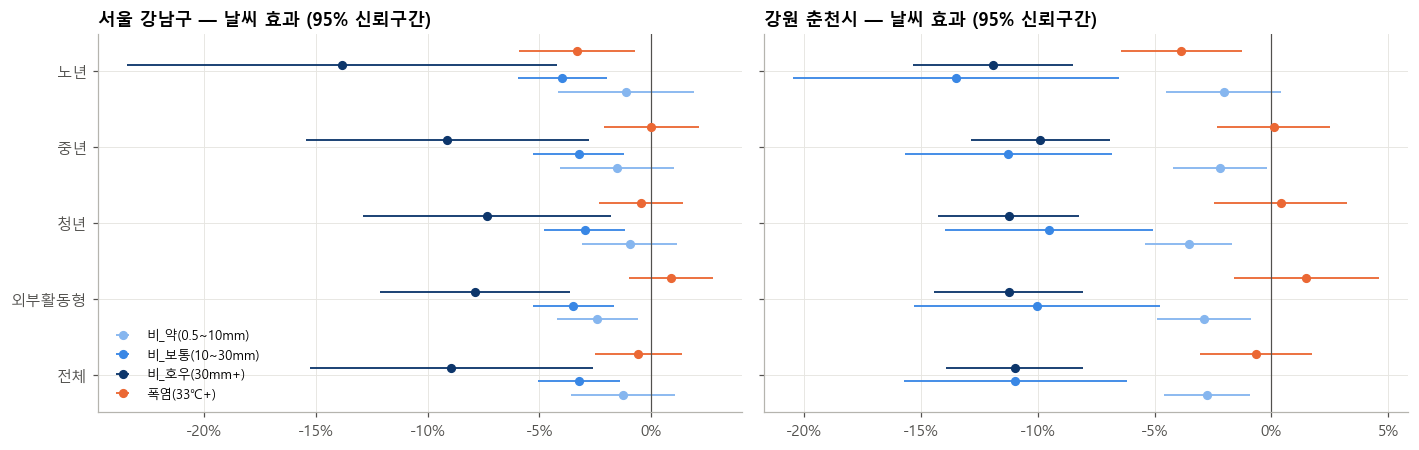

t                                                    효과(%)                                                 
변수           기온편차(℃) 비_보통(10~30mm) 비_약(0.5~10mm) 비_호우(30mm+) 폭염(33℃+) 기온편차(℃) 비_보통(10~30mm) 비_약(0.5~10mm) 비_호우(30mm+) 폭염(33℃+)
지역     집단                                                                                                                     
강원 춘천시 노년      1.700        -3.500        -1.600      -6.400   -2.900   0.200       -13.500        -2.000     -11.900   -3.900
       외부활동형   2.500        -3.500        -2.800      -6.500    1.000   0.300       -10.000        -2.900     -11.200    1.500
       전체      2.500        -4.200        -2.900      -6.900   -0.500   0.300       -11.000        -2.700     -11.000   -0.700
       중년      1.900        -4.700        -2.100      -6.200    0.100   0.200       -11.300        -2.200      -9.900    0.100
       청년      2.900        -4.000        -3.600      -6.900    0.300   0.400        -9.500        -3.500     -11.300    0.400
서울 강남구 노년      1.600        -3.800        -0.700      -2.600   -2.500   0.200        -4.000        -1.100     -13.800   -3.300
       외부활동형   1.800        -3.700        -2.600      -3.500    0.900   0.200        -3.500        -2.400      -7.900    0.900
       전체      2.200        -3.400        -1.100      -2.600   -0.600   0.200        -3.200        -1.300      -8.900   -0.600
       중년      1.400        -3.100        -1.200      -2.700    0.000   0.100        -3.200        -1.500      -9.100    0.000
       청년      2.800        -3.200        -0.900      -2.500   -0.500   0.300        -3.000        -1.000      -7.300   -0.500

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
vars_ = ['비_약(0.5~10mm)', '비_보통(10~30mm)', '비_호우(30mm+)', '폭염(33℃+)']
segs = ['전체', '외부활동형', '청년', '중년', '노년']
for ax, reg in zip(axes, MAIN):
    t = CF[CF['지역'] == reg]
    for j, v in enumerate(vars_):
        tt = t[t['변수'] == v].set_index('집단').reindex(segs)
        y = np.arange(len(segs)) + j * .18 - .27
        ax.errorbar(tt['효과(%)'], y, xerr=1.96 * tt['SE(%)'], fmt='o', ms=5, capsize=0, lw=1.2,
                    color=['#86b6ef', '#3987e5', '#0d366b', '#eb6834'][j], label=v)
    ax.axvline(0, color=INK2, lw=.8); ax.set_yticks(range(len(segs)), segs); ax.set_title(f'{reg}: 날씨 효과 (95% 신뢰구간)')
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
axes[0].legend(fontsize=8.5, loc='lower left'); plt.tight_layout(); plt.show()
CF.pivot_table(index=['지역', '집단'], columns='변수', values=['효과(%)', 't']).round(1)

**판정 기준**: (1) 학습에 없던 주의 오차가 줄어드는가, (2) 비의 효과가 통계적으로 뚜렷한가(|t| ≥ 2), (3) 이상일이 줄어드는가. 세 조건을 모두 만족하면 '보정 변수로서 유의미'로 봅니다. 결과는 7장에 정리했습니다.

## 3. 지역 구조: 코드 대응 · 주민등록 · 'SK 유동인구 = 거주자?'

> **왜** 거주 기반 구조 위험을 붙이고, SK 유동인구가 주민을 대표하는지 확인합니다.  
> **결과** 강남은 SK 유동인구가 주민 수와 무관하고(ρ 0.08), 춘천은 주민 수를 잘 대표합니다(ρ 0.89).


### 3-1. 코드 대응표 (SGIS 8자리 ↔ 행안부 10자리 ↔ 서울 7자리 · 동 이름)

> **왜** 서로 다른 코드 체계 3개를 연결해야 외부 자료를 붙일 수 있습니다.  
> **결과** 47개 읍면동을 모두 연결했고, 일원2동→개포3동 코드 변경도 반영했습니다.


In [7]:
gj = json.load(open(EXT / 'codes/HangJeongDong_ver20250701.geojson', encoding='utf-8'))
cd = pd.DataFrame([f['properties'] for f in gj['features']])
cd = cd[cd['adm_nm'].str.contains('서울특별시 강남구|춘천시')].copy()
cd['지역'] = np.where(cd['adm_nm'].str.contains('강남구'), '서울 강남구', '강원 춘천시')
cd['읍면동명'] = cd['adm_nm'].str.split().str[-1]
CODES = cd.rename(columns={'adm_cd': 'SGIS코드', 'adm_cd2': '행정기관코드'})[['지역', '읍면동명', 'SGIS코드', '행정기관코드']]
# 2023년 일원2동 → 개포3동 명칭·코드 변경: SK·서울 데이터는 구 코드(11230740 / 1123074)를 사용
CODES.loc[CODES['SGIS코드'] == '11230511', ['SGIS코드', '읍면동명']] = ['11230740', '개포3동(구 일원2동)']
CODES['서울7자리'] = CODES['SGIS코드'].str[:7]
n = CODES['SGIS코드'].str[5:8].astype(int)
CODES['유형'] = np.select([n < 300, n < 500], ['읍', '면'], '동')
CODES = CODES.sort_values('SGIS코드').reset_index(drop=True)
CODES.to_csv(EXT / 'codes/읍면동_코드대응표_강남_춘천.csv', index=False, encoding='utf-8-sig')
NAME = dict(zip(CODES['SGIS코드'], CODES['읍면동명']))

# SK 데이터와 코드 일치 확인
sk_codes = set(pd.read_csv(DATA / 'SK_유동인구_성연령.csv', usecols=['소지역코드'], dtype=str)['소지역코드'].str[:8])
print('SK 읍면동 코드(강남·춘천) 중 대응표에 있는 비율:',
      f"{len({c for c in sk_codes if c[:5] in ('11230','32010')} & set(CODES['SGIS코드']))} / {len({c for c in sk_codes if c[:5] in ('11230','32010')})}",
      '| 대응표에만 있는 코드:', set(CODES['SGIS코드']) - sk_codes)
CODES

SK 읍면동 코드(강남·춘천) 중 대응표에 있는 비율: 47 / 47 | 대응표에만 있는 코드: set()


,지역,읍면동명,SGIS코드,행정기관코드,서울7자리,유형
0,서울 강남구,신사동,11230510,1168051000,1123051,동
1,서울 강남구,논현1동,11230520,1168052100,1123052,동
2,서울 강남구,논현2동,11230530,1168053100,1123053,동
3,서울 강남구,삼성1동,11230580,1168058000,1123058,동
4,서울 강남구,삼성2동,11230590,1168059000,1123059,동
5,서울 강남구,대치1동,11230600,1168060000,1123060,동
6,서울 강남구,대치4동,11230630,1168063000,1123063,동
7,서울 강남구,역삼1동,11230640,1168064000,1123064,동
8,서울 강남구,역삼2동,11230650,1168065000,1123065,동
9,서울 강남구,도곡1동,11230660,1168065500,1123066,동


### 3-2. 주민등록 구조 지표 (1인 세대 · 고령 · 청년 · 중장년 남성)

> **왜** 1인 세대·고령 비율은 고독사 위험의 대표적인 구조 요인입니다.  
> **결과** 1인 세대 비율은 강남 8~74%, 춘천 33~75%입니다.

주민등록 자료는 **2026.9.30 기준**입니다(공공데이터포털 최신본). 분석 기간(2025.7~12)과 약 1년 차이가 있습니다.

In [8]:
pop = pd.read_csv(EXT / 'mois/행정동_성별연령별_주민등록인구_20260930.csv', encoding='cp949')
hh = pd.read_csv(EXT / 'mois/행정동_세대원수별_세대수_20260930.csv', encoding='cp949')
pop['행정기관코드'] = pop['행정기관코드'].astype(str); hh['행정기관코드'] = hh['행정기관코드'].astype(str)
pop = pop.merge(CODES[['행정기관코드', 'SGIS코드', '지역', '유형']], on='행정기관코드')
hh = hh.merge(CODES[['행정기관코드', 'SGIS코드']], on='행정기관코드')
print('대응된 읍면동 수:', pop.groupby('지역').size().to_dict())

agecols = {c: (int(re.match(r'(\d+)', c).group(1)), '남성' if '남자' in c else '여성')
           for c in pop.columns if re.match(r'^\d+세', c)}
def a6(a): return '10대' if 10 <= a < 20 else ('60대+' if a >= 60 else (f'{a // 10 * 10}대' if a >= 20 else '0~9세'))
long = pop.melt(id_vars=['SGIS코드', '지역'], value_vars=list(agecols), var_name='col', value_name='주민')
long['나이'] = long['col'].map(lambda c: agecols[c][0]); long['성별'] = long['col'].map(lambda c: agecols[c][1])
long['연령6'] = long['나이'].map(a6)
RES = long.groupby(['SGIS코드', '성별', '연령6'])['주민'].sum()          # 거주 인구 (동 × 성 × 연령)

S = pop.set_index('SGIS코드')[['지역', '유형', '계']].rename(columns={'계': '주민인구'})
S['읍면동명'] = S.index.map(NAME)
S['1인세대비율'] = hh.set_index('SGIS코드')['1인세대'] / hh.set_index('SGIS코드')['전체세대수'] * 100
tot = long.groupby('SGIS코드')['주민'].sum()
S['65세+비율'] = long[long['나이'] >= 65].groupby('SGIS코드')['주민'].sum() / tot * 100
S['20~39세비율'] = long[long['나이'].between(20, 39)].groupby('SGIS코드')['주민'].sum() / tot * 100
S['40~64세 남성비율'] = long[long['나이'].between(40, 64) & (long['성별'] == '남성')].groupby('SGIS코드')['주민'].sum() / tot * 100
S.to_csv(EXT / 'mois/읍면동_구조지표_강남_춘천.csv', encoding='utf-8-sig')
display(S.groupby('지역')[['주민인구', '1인세대비율', '65세+비율', '20~39세비율', '40~64세 남성비율']].describe().T.round(1))
S.sort_values(['지역', '1인세대비율'], ascending=[True, False]).round(1)

대응된 읍면동 수: {'강원 춘천시': 25, '서울 강남구': 22}


지역                    강원 춘천시     서울 강남구
주민인구        count     25.000     22.000
            mean  11,392.000 25,086.700
            std   11,358.500  9,305.900
            min      928.000 12,700.000
            25%    3,215.000 18,631.800
            50%    6,777.000 23,228.500
            75%   18,639.000 30,426.500
            max   44,767.000 45,638.000
1인세대비율      count     25.000     22.000
            mean      49.400     37.400
            std       12.900     17.700
            min       32.700      7.900
            25%       39.000     21.000
            50%       46.300     37.200
            75%       57.600     48.400
            max       75.400     74.400
65세+비율      count     25.000     22.000
            mean      32.100     19.000
            std       13.700      6.500
            min       18.700     11.700
            25%       21.000     15.100
            50%       25.000     18.000
            75%       41.900     20.700
            max       59.200     41.600
20~39세비율    count     25.000     22.000
            mean      21.700     25.300
            std       10.300      7.400
            min        4.700     14.100
            25%       12.800     20.300
            50%       23.000     24.200
            75%       26.200     26.900
            max       43.900     45.500
40~64세 남성비율 count     25.000     22.000
            mean      18.500     18.800
            std        1.700      1.400
            min       14.700     14.800
            25%       17.800     18.500
            50%       18.900     18.700
            75%       19.800     19.400
            max       21.100     21.500

,지역,유형,주민인구,읍면동명,1인세대비율,65세+비율,20~39세비율,40~64세 남성비율
SGIS코드,,,,,,,,
32010520,강원 춘천시,동,3839,교동,75.400,25.000,43.900,14.700
32010640,강원 춘천시,동,12240,효자2동,74.700,24.400,41.200,15.500
32010650,강원 춘천시,동,4253,효자3동,69.000,25.700,39.100,15.000
32010530,강원 춘천시,동,2398,조운동,64.000,36.700,22.700,19.100
32010390,강원 춘천시,면,928,북산면,61.900,59.200,4.700,20.300
32010350,강원 춘천시,면,1006,남면,60.800,55.600,7.000,19.800
32010600,강원 춘천시,동,10690,후평1동,57.600,30.000,26.600,17.800
32010360,강원 춘천시,면,3215,남산면,56.100,48.600,9.600,21.100
32010380,강원 춘천시,면,2238,사북면,56.000,52.800,8.300,16.900


### 3-3. SK 유동인구는 거주 인구를 대표하는가

> **왜** SK 지표를 주민 행동으로 읽어도 되는지 확인합니다.  
> **결과** 강남은 대표하지 못하고(주간 유입이 큼), 춘천은 대표합니다. 60대+ 비중은 두 지역 모두 중간 정도로 일치합니다(ρ 0.55~0.62).


,지역,비교,스피어만 ρ,p,n
0,서울 강남구,SK 일평균 유동 ↔ 주민인구,0.081,0.721,22
1,서울 강남구,SK 야간(00~05) 평균 ↔ 주민인구,0.133,0.556,22
2,서울 강남구,SK 60대+ 비중 ↔ 주민 60대+ 비중,0.549,0.008,22
3,강원 춘천시,SK 일평균 유동 ↔ 주민인구,0.888,0.000,25
4,강원 춘천시,SK 야간(00~05) 평균 ↔ 주민인구,0.888,0.000,25
5,강원 춘천시,SK 60대+ 비중 ↔ 주민 60대+ 비중,0.624,0.001,25


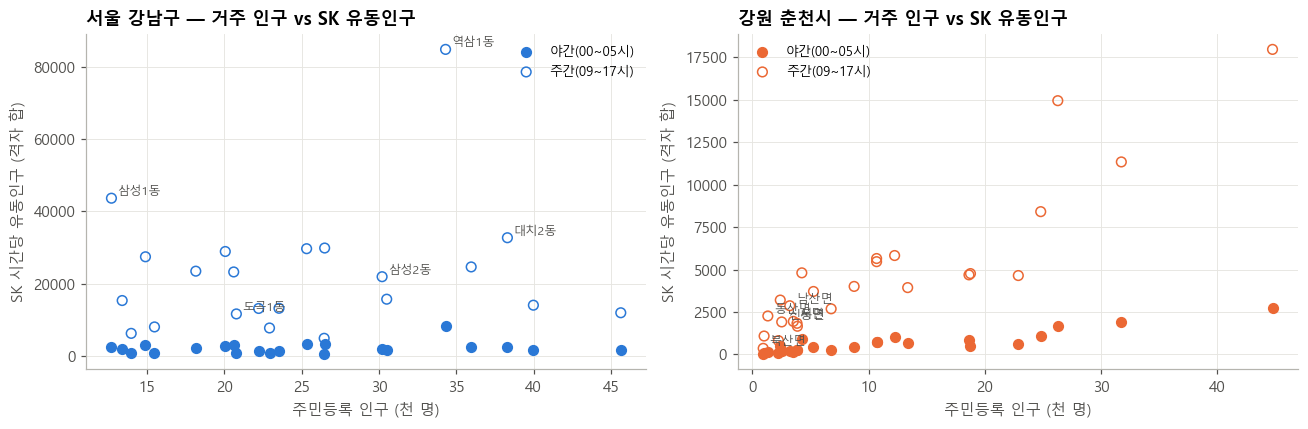

In [9]:
# SK 유동인구(성연령, 6개월 평균)와 SK 야간(00~05시) 유동인구를 거주 인구와 비교
age = pd.read_csv(DATA / 'SK_유동인구_성연령.csv', dtype={'기준년월': str, '소지역코드': str})
age['SGIS코드'] = age['소지역코드'].str[:8]; age = age[age['SGIS코드'].isin(CODES['SGIS코드'])]
MC = [c for c in age.columns if c.startswith('남자')]; FC = [c for c in age.columns if c.startswith('여자')]
SKA = ['10대', '20대', '30대', '40대', '50대', '60대+']
skl = age.groupby(['SGIS코드', '기준년월'])[MC + FC].sum().stack().rename('유동').reset_index()
skl['성별'] = np.where(skl['level_2'].str.startswith('남자'), '남성', '여성')
skl['연령6'] = skl['level_2'].map(dict(zip(MC + FC, SKA * 2)))
tm = pd.read_csv(DATA / 'SK_유동인구_시간대.csv', dtype={'기준년월': str, '소지역코드': str})
tm['SGIS코드'] = tm['소지역코드'].str[:8]; tm = tm[tm['SGIS코드'].isin(CODES['SGIS코드'])]
TM = [f'유동인구수_{h:02d}시간대' for h in range(24)]
wk = pd.read_csv(DATA / 'SK_유동인구_요일.csv', dtype={'기준년월': str, '소지역코드': str})
wk['SGIS코드'] = wk['소지역코드'].str[:8]; wk = wk[wk['SGIS코드'].isin(CODES['SGIS코드'])]
WD = [f'{d}요일 유동인구' for d in '월화수목금토일']

S['SK 일평균 유동'] = skl.groupby('SGIS코드')['유동'].sum() / 6
S['SK 야간(00~05) 평균'] = tm.groupby('SGIS코드')[TM[:6]].sum().sum(axis=1) / 6 / 6
S['SK 주간(09~17) 평균'] = tm.groupby('SGIS코드')[TM[9:18]].sum().sum(axis=1) / 9 / 6
S['주간/야간'] = S['SK 주간(09~17) 평균'] / S['SK 야간(00~05) 평균']
S['주말/평일'] = wk.groupby('SGIS코드')[WD[5:]].sum().mean(axis=1) / wk.groupby('SGIS코드')[WD[:5]].sum().mean(axis=1)
sk60 = skl[skl['연령6'] == '60대+'].groupby('SGIS코드')['유동'].sum() / skl.groupby('SGIS코드')['유동'].sum() * 100
res60 = RES.xs('60대+', level='연령6').groupby('SGIS코드').sum() / RES.groupby('SGIS코드').sum() * 100
S['SK 60대+ 비중'] = sk60; S['주민 60대+ 비중'] = res60

rows = []
for reg in MAIN:
    s = S[S['지역'] == reg].dropna()
    for a, b in [('SK 일평균 유동', '주민인구'), ('SK 야간(00~05) 평균', '주민인구'), ('SK 60대+ 비중', '주민 60대+ 비중')]:
        r, p = spearmanr(s[a], s[b]); rows.append({'지역': reg, '비교': f'{a} ↔ {b}', '스피어만 ρ': r, 'p': p, 'n': len(s)})
display(pd.DataFrame(rows).round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, reg in zip(axes, MAIN):
    s = S[S['지역'] == reg]
    ax.scatter(s['주민인구'] / 1e3, s['SK 야간(00~05) 평균'], color=C[reg], s=40, label='야간(00~05시)')
    ax.scatter(s['주민인구'] / 1e3, s['SK 주간(09~17) 평균'], facecolor='none', edgecolor=C[reg], s=40, label='주간(09~17시)')
    for code_, row in s.iterrows():
        if row['주간/야간'] > s['주간/야간'].quantile(.8): ax.annotate(row['읍면동명'], (row['주민인구'] / 1e3, row['SK 주간(09~17) 평균']), fontsize=8, color=INK2, xytext=(4, 2), textcoords='offset points')
    ax.set_xlabel('주민등록 인구 (천 명)'); ax.set_ylabel('SK 시간당 유동인구 (격자 합)'); ax.set_title(f'{reg}: 거주 인구 vs SK 유동인구'); ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

## 4. 강남구 정답 데이터 탐색: 서울 '행정동단위 10개 관심집단수'

> **왜** 모델 성능을 검증하려면 '정답'이 필요합니다.  
> **결과** 강남 22개 동 × 성 × 연령 × 6개월의 정답 데이터를 확보했고, 개포3동의 데이터 결함을 발견했습니다.


매뉴얼(`seoul_living_docs/서울시민생활데이터_매뉴얼.pdf` p.17, p.22) 기준 정의입니다.
- **커뮤니케이션이 적은 집단**: 서울 1인가구 중 통화·문자 대상자 수, 통화·문자량, SNS 사용량 지수 **하위 10%**
- **재정상태 관심집단**: 1인가구 중 소액결제·요금 연체 지수 **상위 10%**
- **외출이 매우 적은 집단(전체)**, **외출-커뮤니케이션이 모두 적은 집단(전체)**: 1인가구가 아닌 **전체 인구** 중 연령대별 해당 확률 **상위 2%**
- 모든 값은 SKT 가명결합 데이터로 로지스틱 회귀를 적합한 뒤 시장점유율로 전수화한 **추정치**입니다.

분석 단위는 동 22개 × 성 2개 × 연령 5구간(20대~60대+) × 6개월 = 1,320행입니다.

In [10]:
fs = sorted((EXT / 'seoul_interest').glob('interest_2025_*.xlsx'))
si = pd.concat([pd.read_excel(f).assign(기준년월='2025' + f.stem[-2:]) for f in fs])
si = si.loc[:, ~si.columns.astype(str).str.startswith('Unnamed')]
si = si[si['자치구'] == '강남구'].copy()
si['SGIS코드'] = si['행정동코드'].astype(str) + '0'      # 서울 7자리 + '0' = SGIS 8자리
assert si['SGIS코드'].isin(CODES['SGIS코드']).all()
si['성별'] = si['성별'].map({1: '남성', 2: '여성'})
si['연령6'] = si['연령대'].map(lambda a: '60대+' if a >= 60 else f'{a // 10 * 10}대')
print('동 매칭:', si['SGIS코드'].notna().mean(), '| 동 수', si['SGIS코드'].nunique())
G = ['커뮤니케이션이 적은 집단', '평일 외출이 적은 집단', '휴일 외출이 적은 집단', '외출이 매우 적은 집단(전체)',
     '외출-커뮤니케이션이 모두 적은 집단(전체)', '재정상태에 대한 관심집단']
T = si.groupby(['SGIS코드', '성별', '연령6', '기준년월'])[['총인구', '1인가구수'] + G].sum()
T['고립(외출·소통 모두 적음, 인구 %)'] = T['외출-커뮤니케이션이 모두 적은 집단(전체)'] / T['총인구'] * 100
T['외출 매우 적음(인구 %)'] = T['외출이 매우 적은 집단(전체)'] / T['총인구'] * 100
T['소통 적음(1인가구 %)'] = T['커뮤니케이션이 적은 집단'] / T['1인가구수'] * 100
T['재정 관심(1인가구 %)'] = T['재정상태에 대한 관심집단'] / T['1인가구수'] * 100
T['1인가구 비율(%)'] = T['1인가구수'] / T['총인구'] * 100
TG = ['고립(외출·소통 모두 적음, 인구 %)', '외출 매우 적음(인구 %)', '소통 적음(1인가구 %)', '재정 관심(1인가구 %)']
zero = T.groupby('SGIS코드')[G].apply(lambda g: (g == 0).mean() * 100)
zero = zero[(zero > 50).any(axis=1)]
if len(zero): print('관심집단 값이 절반 이상 0인 동 (데이터 품질 의심):'); display(zero.rename(index=NAME).round(0))
T = T.reset_index(); T['읍면동명'] = T['SGIS코드'].map(NAME)
# 총인구 정합성 (서울 데이터 vs 주민등록)
chk = T[T['기준년월'] == '202512'].groupby('SGIS코드')['총인구'].sum().to_frame('서울데이터 20세+').join(
      RES.drop(['0~9세', '10대'], level='연령6', errors='ignore').groupby('SGIS코드').sum().rename('주민등록 20세+'), how='left')
print('총인구 비교 스피어만 ρ:', round(spearmanr(chk.iloc[:, 0], chk.iloc[:, 1])[0], 3),
      '| 비율 중앙값(서울/주민등록):', round((chk.iloc[:, 0] / chk.iloc[:, 1]).median(), 3))
T[TG].describe().round(2)

동 매칭: 1.0 | 동 수 22
관심집단 값이 절반 이상 0인 동 (데이터 품질 의심):


,커뮤니케이션이 적은 집단,평일 외출이 적은 집단,휴일 외출이 적은 집단,외출이 매우 적은 집단(전체),외출-커뮤니케이션이 모두 적은 집단(전체),재정상태에 대한 관심집단
SGIS코드,,,,,,
개포3동(구 일원2동),100.000,100.000,100.000,0.000,0.000,100.000


총인구 비교 스피어만 ρ: 0.958 | 비율 중앙값(서울/주민등록): 1.121


,"고립(외출·소통 모두 적음, 인구 %)",외출 매우 적음(인구 %),소통 적음(1인가구 %),재정 관심(1인가구 %)
count,"1,320.000","1,320.000","1,320.000","1,320.000"
mean,2.140,2.120,10.180,7.920
std,0.930,1.070,4.440,3.100
min,0.360,0.000,0.000,0.000
25%,1.500,1.300,7.040,6.230
50%,1.990,1.980,9.790,8.120
75%,2.630,2.690,13.460,9.950
max,8.670,6.180,21.710,17.990


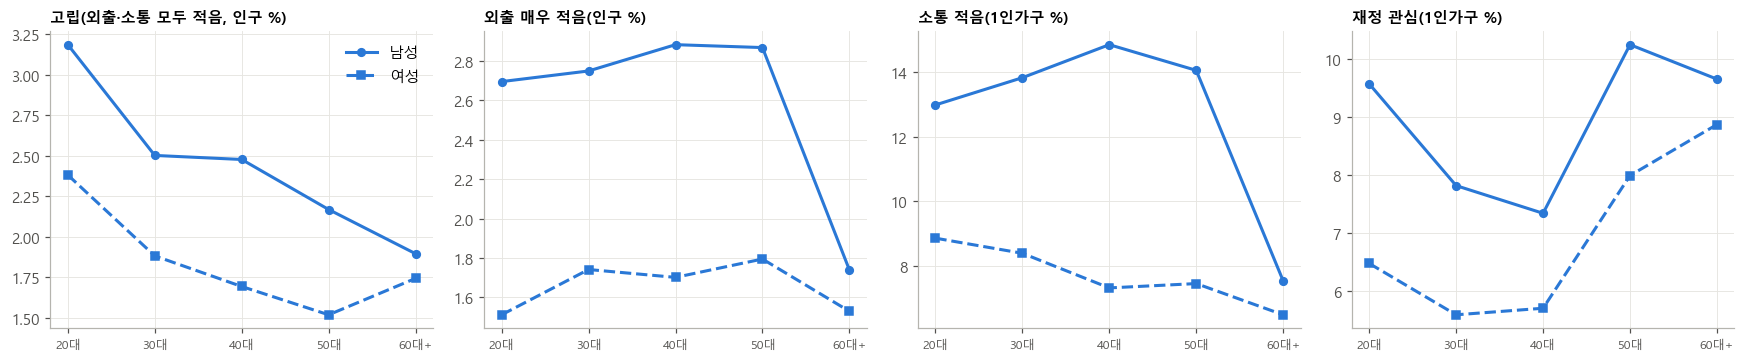

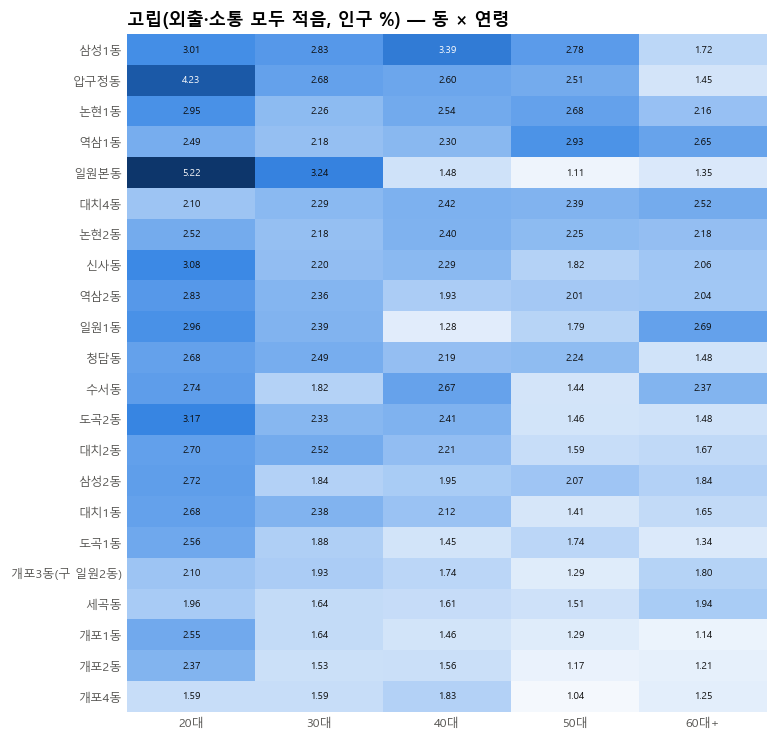

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, t in zip(axes, TG):
    g = T.groupby(['연령6', '성별'])[t].mean().unstack().reindex(AGE5)
    for sx, ls, mk in (('남성', '-', 'o'), ('여성', '--', 's')): ax.plot(AGE5, g[sx], ls=ls, marker=mk, color=C['서울 강남구'], ms=5, label=sx)
    ax.set_title(t, fontsize=10); ax.tick_params(axis='x', labelsize=8)
axes[0].legend(); plt.tight_layout(); plt.show()

# 동 × 연령 (6개월·성별 평균): 주 타깃
TGT = TG[0]
hm = T.groupby(['읍면동명', '연령6'])[TGT].mean().unstack()[AGE5]
hm = hm.loc[hm.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(7.5, 8)); heat(ax, hm, fmt='{:.2f}'); ax.set_title(f'{TGT}: 동 × 연령'); plt.show()

### 4-1. 정답 데이터의 월별 안정성: 같은 (동·성·연령)의 값이 달마다 얼마나 일관된가

> **왜** 정답이 흔들리면 모델 평가도 흔들립니다.  
> **결과** 주 타깃의 인접월 순위 상관은 0.80, 소통 적음은 0.98입니다.


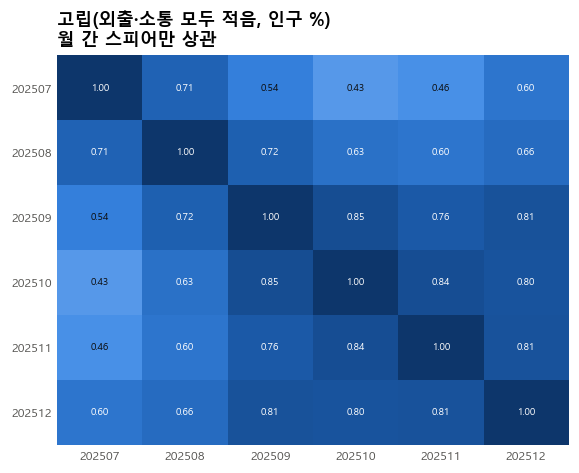

,인접월 평균 ρ,7월↔12월 ρ
"고립(외출·소통 모두 적음, 인구 %)",0.786,0.600
외출 매우 적음(인구 %),0.900,0.798
소통 적음(1인가구 %),0.982,0.966
재정 관심(1인가구 %),0.971,0.908


In [12]:
stab = {}
for t in TG:
    p = T.pivot_table(index=['SGIS코드', '성별', '연령6'], columns='기준년월', values=t)
    c = p.corr(method='spearman'); stab[t] = {'인접월 평균 ρ': np.mean([c.iloc[i, i + 1] for i in range(5)]), '7월↔12월 ρ': c.iloc[0, 5]}
    # 동 순위의 안정성 (성·연령 표준화 후)
STAB = pd.DataFrame(stab).T
fig, ax = plt.subplots(figsize=(6, 4.6))
heat(ax, T.pivot_table(index=['SGIS코드', '성별', '연령6'], columns='기준년월', values=TGT).corr(method='spearman'), fmt='{:.2f}', vmin=0, vmax=1)
ax.set_title(f'{TGT}\n월 간 스피어만 상관'); plt.show()
STAB.round(3)

## 5. 정답 예측 모델 검증: 우리 데이터로 강남구 고립 지표를 맞힐 수 있는가

> **왜** 우리 데이터가 동 간 차이를 설명하는지 검증합니다.  
> **결과** 같은 성·연령 안에서 동 순위 ρ 0.36~0.51을 보였습니다(기본값 0). 카드와 LGBM을 더해도 추가 이득이 없었습니다.


**핵심 질문**: 성·연령만 알면 되는가(기본값), 아니면 SK 유동인구·주민등록·카드 정보가 **동 간 차이**를 추가로 설명하는가?

| 모델 | 입력 변수 |
|---|---|
| M0 기본값 | 같은 (성·연령·월)의 다른 동 평균: 사회조사식 '성·연령 기본 위험률'과 같은 역할 |
| M1 SK | 성·연령 + SK (동·집단 유동인구, 유동/거주 비, 주간/야간, 주말/평일, 60대+ 비중) |
| M2 SK+주민등록 | M1 + 동 1인세대 비율·65세+ 비율 |
| M3 전체(LightGBM) | M2 + 카드(강남구 성·연령·월 단위: 외부활동·편의점·심야·의료 비중) |

**검증**: 동 하나를 통째로 빼고 학습한 뒤 그 동을 예측합니다(Leave-One-Dong-Out, 22회).
**지표**: R², MAE, 그리고 **같은 성·연령·월 안에서 22개 동의 순위를 맞히는 정도**(스피어만 ρ). 우선 지원 동을 고르는 데에는 이 순위 지표가 핵심입니다.

In [13]:
%%time
# --- 특징 생성 (강남)
ft = skl[skl['연령6'] != '10대'].merge(T[['SGIS코드', '성별', '연령6', '기준년월'] + TG + ['총인구']],
                                      on=['SGIS코드', '성별', '연령6', '기준년월'], how='inner')
ft = ft.groupby(['SGIS코드', '성별', '연령6', '기준년월'], as_index=False).agg({**{t: 'first' for t in TG}, '유동': 'sum', '총인구': 'first'})
resid = RES.rename('주민').reset_index()
ft = ft.merge(resid, on=['SGIS코드', '성별', '연령6'], how='left')
ft['log 집단 유동'] = np.log1p(ft['유동'])
ft['유동/거주 비'] = np.log((ft['유동'] + 1) / (ft['주민'] + 1))
dong_m = skl.groupby(['SGIS코드', '기준년월'])['유동'].sum().rename('동유동')
ft = ft.merge(dong_m.reset_index(), on=['SGIS코드', '기준년월'])
ft['집단 유동 비중'] = ft['유동'] / ft['동유동']
ft['log 동 유동'] = np.log(ft['동유동'])
tmm = tm.groupby(['SGIS코드', '기준년월'])[TM].sum()
ft = ft.merge(((tmm[TM[9:18]].sum(axis=1) / 9) / (tmm[TM[:6]].sum(axis=1) / 6)).rename('주간/야간').reset_index(), on=['SGIS코드', '기준년월'])
wkm = wk.groupby(['SGIS코드', '기준년월'])[WD].sum()
ft = ft.merge((wkm[WD[5:]].mean(axis=1) / wkm[WD[:5]].mean(axis=1)).rename('주말/평일').reset_index(), on=['SGIS코드', '기준년월'])
ft = ft.merge(S[['1인세대비율', '65세+비율']].reset_index(), on='SGIS코드')
cg = card[card['지역'] == '서울 강남구'].copy(); cg['연령6'] = cg['연령5']
base = cg.groupby(['성별', '연령6', '기준년월'])['건수'].sum()
cf = pd.DataFrame({'카드 외부활동%': cg[cg['업종'].isin(OUTD)].groupby(['성별', '연령6', '기준년월'])['건수'].sum() / base * 100,
                   '카드 편의점%': cg[cg['업종'] == '편의점'].groupby(['성별', '연령6', '기준년월'])['건수'].sum() / base * 100,
                   '카드 심야%': cg[cg['시간대'] == '00_05'].groupby(['성별', '연령6', '기준년월'])['건수'].sum() / base * 100,
                   '카드 의료%': cg[cg['업종'].isin(MED)].groupby(['성별', '연령6', '기준년월'])['건수'].sum() / base * 100}).reset_index()
ft = ft.merge(cf, on=['성별', '연령6', '기준년월'], how='left')
ft = ft[ft['SGIS코드'] != '11230740'].reset_index(drop=True)   # 개포3동(구 일원2동): 정답 데이터 결함(1인가구 기반 값 전부 0) → 제외, 21개 동
ft['grp'] = ft['성별'] + '_' + ft['연령6']; ft['cell'] = ft['grp'] + '_' + ft['기준년월']
dummies = pd.get_dummies(ft[['grp', '기준년월']], dtype=float)
F_SK = ['log 집단 유동', '유동/거주 비', '집단 유동 비중', 'log 동 유동', '주간/야간', '주말/평일']
F_RES = ['1인세대비율', '65세+비율']
F_CARD = ['카드 외부활동%', '카드 편의점%', '카드 심야%', '카드 의료%']
print('모델링 행 수:', len(ft), '| 결측:', int(ft[F_SK + F_RES + F_CARD].isna().sum().sum()))

def within_rho(df, pred):
    rs = []
    for _, g in df.assign(_p=pred).groupby('cell'):
        if g['_p'].nunique() > 1 and len(g) > 4: rs.append(spearmanr(g['_p'], g['_y'])[0])
        else: rs.append(0.0)
    return np.array(rs)

def evaluate(target):
    df = ft.assign(_y=ft[target]).reset_index(drop=True); y = df['_y'].values; groups = df['SGIS코드'].values
    preds = {k: np.zeros(len(df)) for k in ['M0 기본값', 'M1 SK', 'M2 SK+주민등록', 'M3 전체(LGBM)']}
    Xs = {'M1 SK': pd.concat([dummies, df[F_SK]], axis=1), 'M2 SK+주민등록': pd.concat([dummies, df[F_SK + F_RES]], axis=1),
          'M3 전체(LGBM)': pd.concat([dummies, df[F_SK + F_RES + F_CARD]], axis=1)}
    for tr, te in LeaveOneGroupOut().split(df, y, groups):
        m0 = df.iloc[tr].groupby('cell')['_y'].mean(); preds['M0 기본값'][te] = df.iloc[te]['cell'].map(m0).values
        for k in ['M1 SK', 'M2 SK+주민등록']:
            mdl = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 20))).fit(Xs[k].iloc[tr], y[tr])
            preds[k][te] = mdl.predict(Xs[k].iloc[te])
        g = lgb.LGBMRegressor(n_estimators=300, learning_rate=.03, num_leaves=7, min_child_samples=15, subsample=.8,
                              subsample_freq=1, colsample_bytree=.8, verbose=-1, random_state=0)
        preds['M3 전체(LGBM)'][te] = g.fit(Xs['M3 전체(LGBM)'].iloc[tr], y[tr]).predict(Xs['M3 전체(LGBM)'].iloc[te])
    rows = []
    for k, p in preds.items():
        wr = np.zeros(df['cell'].nunique()) if k == 'M0 기본값' else within_rho(df, p)   # 기본값은 동을 구분 못함 → 정의상 0
        rows.append({'타깃': target, '모델': k, 'R²': 1 - ((y - p) ** 2).sum() / ((y - y.mean()) ** 2).sum(),
                     'MAE': np.abs(y - p).mean(), '동 순위 ρ(평균)': wr.mean(),
                     '동 순위 ρ 95%CI': f"{np.percentile([np.random.default_rng(i).choice(wr, len(wr)).mean() for i in range(500)], 2.5):.2f}~"
                                        f"{np.percentile([np.random.default_rng(i).choice(wr, len(wr)).mean() for i in range(500)], 97.5):.2f}"})
    return pd.DataFrame(rows), preds, df

RESULTS, PREDS = [], {}
for t in TG:
    r, p, dfx = evaluate(t); RESULTS.append(r); PREDS[t] = (p, dfx)
RESULTS = pd.concat(RESULTS)
RESULTS.round(3)

모델링 행 수: 1260 | 결측: 0


CPU times: total: 41.5 s
Wall time: 17.6 s


,타깃,모델,R²,MAE,동 순위 ρ(평균),동 순위 ρ 95%CI
0,"고립(외출·소통 모두 적음, 인구 %)",M0 기본값,0.282,0.589,0.000,0.00~0.00
1,"고립(외출·소통 모두 적음, 인구 %)",M1 SK,0.337,0.547,0.376,0.31~0.44
2,"고립(외출·소통 모두 적음, 인구 %)",M2 SK+주민등록,0.281,0.568,0.357,0.29~0.42
3,"고립(외출·소통 모두 적음, 인구 %)",M3 전체(LGBM),0.271,0.568,0.319,0.25~0.38
0,외출 매우 적음(인구 %),M0 기본값,0.221,0.766,0.000,0.00~0.00
1,외출 매우 적음(인구 %),M1 SK,0.422,0.616,0.464,0.39~0.54
2,외출 매우 적음(인구 %),M2 SK+주민등록,0.393,0.636,0.464,0.40~0.53
3,외출 매우 적음(인구 %),M3 전체(LGBM),0.487,0.586,0.428,0.34~0.51
0,소통 적음(1인가구 %),M0 기본값,0.671,1.801,0.000,0.00~0.00
1,소통 적음(1인가구 %),M1 SK,0.782,1.429,0.494,0.42~0.57


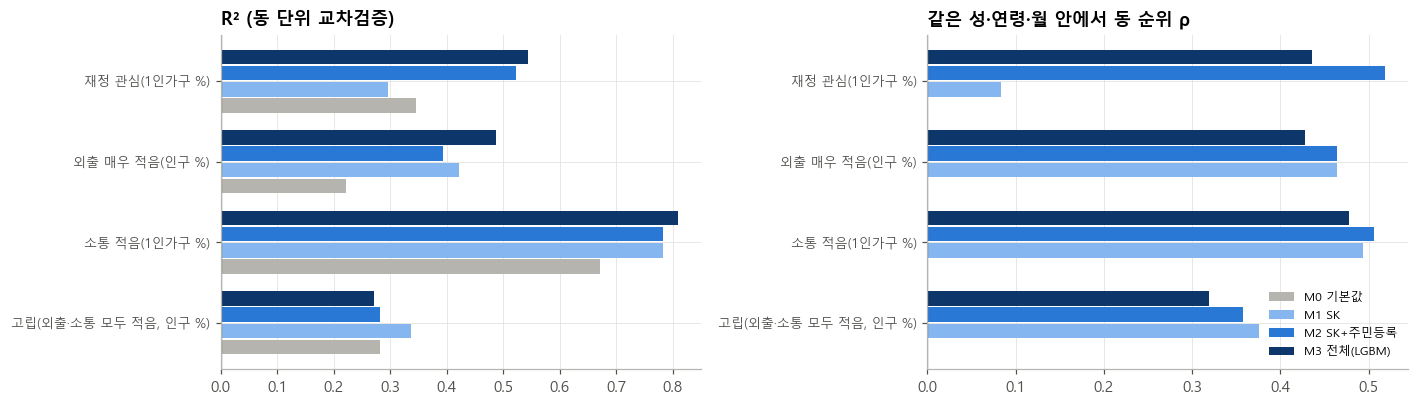

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
piv = RESULTS.pivot(index='타깃', columns='모델', values='R²')[['M0 기본값', 'M1 SK', 'M2 SK+주민등록', 'M3 전체(LGBM)']]
piv2 = RESULTS.pivot(index='타깃', columns='모델', values='동 순위 ρ(평균)')[piv.columns]
for ax, P_, tt in [(axes[0], piv, 'R² (동 단위 교차검증)'), (axes[1], piv2, '같은 성·연령·월 안에서 동 순위 ρ')]:
    x = np.arange(len(P_)); w = .2
    for i, (mname, col) in enumerate(zip(P_.columns, [GRAY, '#86b6ef', '#2a78d6', '#0d366b'])):
        ax.barh(x + (i - 1.5) * w, P_[mname], height=w - .02, color=col, label=mname)
    ax.set_yticks(x, P_.index, fontsize=8.5); ax.axvline(0, color=INK2, lw=.8); ax.set_title(tt)
axes[1].legend(fontsize=8, loc='lower right'); plt.tight_layout(); plt.show()

### 5-1. 무엇이 설명하는가: M2(Ridge) 표준화 계수와 동 단위 상관

> **왜** 무엇이 설명력을 주는지 확인합니다.  
> **결과** 동 고유 고립 수준은 SK 야간 유동(0.62)·1인 세대(0.46)와 관련이 있고, 65세+ 비율(0.09)과는 무관합니다.


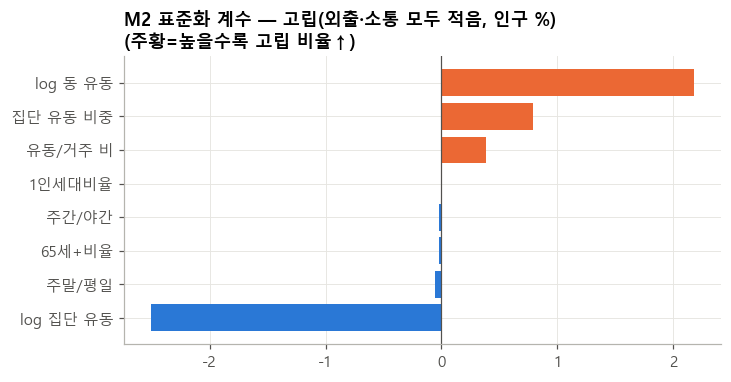

,ρ,p
1인세대비율,0.462,0.035
65세+비율,0.090,0.699
주간/야간,0.373,0.096
주말/평일,-0.373,0.096
SK 야간(00~05) 평균,0.623,0.003
주민인구,-0.439,0.047


,동 고유 고립수준,읍면동명,1인세대비율,65세+비율,주간/야간,주말/평일,SK 야간(00~05) 평균,주민인구
SGIS코드,,,,,,,,
11230580,0.584,삼성1동,36.830,21.362,17.325,0.759,"2,520.439",12700
11230770,0.532,압구정동,26.716,22.526,8.924,0.827,"3,331.305",25322
11230520,0.359,논현1동,69.741,16.227,7.752,0.657,"3,006.707",20607
11230640,0.350,역삼1동,74.405,12.411,10.243,0.561,"8,274.326",34307
11230720,0.320,일원본동,18.471,18.308,9.823,0.623,"1,346.768",22220
11230630,0.184,대치4동,55.995,13.214,10.220,0.845,"2,301.807",18155
11230530,0.145,논현2동,56.819,17.376,9.754,0.607,"2,968.785",20062
11230510,0.130,신사동,37.663,22.208,8.708,0.846,"3,157.513",14900
11230650,0.073,역삼2동,41.137,11.740,9.321,0.648,"2,649.607",35964


In [15]:
df = ft.assign(_y=ft[TGT])
mdl = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 20))).fit(pd.concat([dummies, df[F_SK + F_RES]], axis=1), df['_y'])
coef = pd.Series(mdl[-1].coef_, index=list(dummies.columns) + F_SK + F_RES).loc[F_SK + F_RES].sort_values()
fig, ax = plt.subplots(figsize=(7, 3.4)); ax.barh(coef.index, coef.values, color=[C['강원 춘천시'] if v > 0 else C['서울 강남구'] for v in coef.values])
ax.axvline(0, color=INK2, lw=.8); ax.set_title(f'M2 표준화 계수: {TGT}\n(주황=높을수록 고립 비율↑)'); plt.show()

# 동 단위(22개): 성·연령·월 효과를 뺀 '동 고유 수준' vs 동 특징
df['잔차'] = df['_y'] - df.groupby('cell')['_y'].transform('mean')
dl = df.groupby('SGIS코드')['잔차'].mean().rename('동 고유 고립수준').to_frame().join(S[['읍면동명', '1인세대비율', '65세+비율', '주간/야간', '주말/평일', 'SK 야간(00~05) 평균', '주민인구']])
cor = pd.DataFrame({c: spearmanr(dl['동 고유 고립수준'], dl[c]) for c in ['1인세대비율', '65세+비율', '주간/야간', '주말/평일', 'SK 야간(00~05) 평균', '주민인구']}, index=['ρ', 'p']).T
display(cor.round(3))
dl.sort_values('동 고유 고립수준', ascending=False).round(3)

## 6. 춘천 적용 (참고용)

> **왜** 강남에서 학습한 관계를 춘천에 쓸 수 있는지 점검합니다.  
> **결과** 특징값의 상당수가 학습 범위 밖이라 참고용입니다.

강남에서 학습한 M2를 춘천에 그대로 적용합니다. **도메인이 다르므로(도시 vs 도농복합, 1인가구 구성 차이) 검증되지 않은 외삽입니다.** 순위 참고용으로만 보세요.

In [16]:
ch = skl[(skl['SGIS코드'].str[:5] == '32010') & (skl['연령6'] != '10대')].groupby(['SGIS코드', '성별', '연령6', '기준년월'], as_index=False)['유동'].sum()
ch = ch.merge(resid, on=['SGIS코드', '성별', '연령6'], how='left')
ch['log 집단 유동'] = np.log1p(ch['유동']); ch['유동/거주 비'] = np.log((ch['유동'] + 1) / (ch['주민'] + 1))
ch = ch.merge(dong_m.reset_index(), on=['SGIS코드', '기준년월']); ch['집단 유동 비중'] = ch['유동'] / ch['동유동']; ch['log 동 유동'] = np.log(ch['동유동'])
ch = ch.merge(((tmm[TM[9:18]].sum(axis=1) / 9) / (tmm[TM[:6]].sum(axis=1) / 6)).rename('주간/야간').reset_index(), on=['SGIS코드', '기준년월'])
ch = ch.merge((wkm[WD[5:]].mean(axis=1) / wkm[WD[:5]].mean(axis=1)).rename('주말/평일').reset_index(), on=['SGIS코드', '기준년월'])
ch = ch.merge(S[['1인세대비율', '65세+비율']].reset_index(), on='SGIS코드')
ch['grp'] = ch['성별'] + '_' + ch['연령6']
dch = pd.get_dummies(ch[['grp', '기준년월']], dtype=float).reindex(columns=dummies.columns, fill_value=0)
ch['예측 고립(%)'] = mdl.predict(pd.concat([dch, ch[F_SK + F_RES]], axis=1))
# 외삽 정도: 강남 학습 범위를 벗어난 특징 비율
rng = ft[F_SK + F_RES].quantile([.01, .99])
outside = ((ch[F_SK + F_RES] < rng.loc[.01]) | (ch[F_SK + F_RES] > rng.loc[.99])).mean() * 100
print('춘천 특징값이 강남 학습 범위(1~99%) 밖인 비율(%):'); display(outside.round(1).to_frame('범위 밖 %').T)
chr_ = ch.groupby('SGIS코드').apply(lambda g: g['예측 고립(%)'].mean()).rename('예측 고립(%)').to_frame().join(S[['읍면동명', '유형', '1인세대비율', '65세+비율']])
chr_.sort_values('예측 고립(%)', ascending=False).round(2)

춘천 특징값이 강남 학습 범위(1~99%) 밖인 비율(%):


,log 집단 유동,유동/거주 비,집단 유동 비중,log 동 유동,주간/야간,주말/평일,1인세대비율,65세+비율
범위 밖 %,50.700,3.800,9.900,71.300,28.700,32.000,8.000,32.000


,예측 고립(%),읍면동명,유형,1인세대비율,65세+비율
SGIS코드,,,,,
32010390,2.970,북산면,면,61.940,59.160
32010320,2.560,동산면,면,53.900,51.960
32010530,2.470,조운동,동,64.010,36.660
32010650,2.460,효자3동,동,69.020,25.680
32010350,2.420,남면,면,60.780,55.570
32010380,2.340,사북면,면,55.960,52.770
32010330,2.300,신동면,면,38.980,41.910
32010520,2.210,교동,동,75.450,24.980
32010360,2.150,남산면,면,56.150,48.650


## 7. 전문가 관점 평가 · 결론

> **왜** 결과의 한계와 프로젝트 방향을 정리합니다.  
> **결과** '판단도구 현장 조사 우선순위 추천' 에이전트로 방향을 잡는 것을 권합니다.


### 7-1. 결과 요약

| 검증 항목 | 결과 | 판정 |
|---|---|---|
| **날씨 보정** (기상청 ASOS) | 처음 보는 주의 예측 오차가 강남 4~10%, 춘천 13~21% 줄었습니다. 호우(30mm+)일 소비는 −7~−14%, 보통 비는 춘천 −10~−14%·강남 −3~−4%입니다. 이상일은 춘천 전체 7→2일, 청년 8→1일로 줄었습니다. 처음 쓴 Meteostat은 기상청과의 강수 상관이 0.78~0.80에 그쳐 효과를 작게 잡았습니다. | **유의미** (보정 변수로서) |
| **SK 유동인구가 거주 인구를 대표하는가** | 동별 유동인구와 주민 수의 순위 상관이 강남 0.08~0.13, 춘천 0.89입니다. 60대+ 비중 상관은 강남 0.55, 춘천 0.62입니다. | 강남 **불가**, 춘천 **가능** |
| **강남 정답 지표를 맞히는가** (21개 동을 하나씩 빼고 검증) | 성·연령 기본값만 쓴 M0는 동을 구분하지 못합니다(순위 ρ=0). SK를 더하면 같은 성·연령·월 안에서 동 순위 ρ가 0.36~0.51로 오릅니다. 재정 관심 지표는 주민등록(1인세대 비율)이 있어야 0.52가 나옵니다. 카드와 LightGBM을 더해도 추가 이득은 없었습니다. | **부분적으로 설명** (순위 보조 수준) |
| **강남에서 고립 지표가 높은 동의 특징** | 동 고유 고립 수준은 SK 야간 유동(ρ 0.62)·1인세대 비율(ρ 0.46)과 관련이 있고, 65세+ 비율(ρ 0.09)과는 무관합니다. 상위 동은 삼성1·압구정·논현1·역삼1동입니다. | '고령 동'이 아니라 **1인가구 밀집 동** |
| **강남 모델을 춘천에 적용** | 춘천 특징값의 상당수가 강남 학습 범위 밖입니다(동 유동 71%, 65세+ 비율 32%). | **참고용** (외삽) |

### 7-2. 데이터 전문가 관점: 약점
1. **'정답'이 실제 고립이 아닙니다.** 타깃도 SKT 가명결합 데이터로 만든 로지스틱 회귀 **추정치**입니다. 정의도 조작적이라, 1인가구 하위 10%·전체 상위 2% 같은 **서울 내 상대 순위**입니다. 결국 '모델로 모델을 맞히는' 구조이고, 같은 통신사 데이터에서 나와 측정 오차를 공유합니다(순환성). 따라서 성능이 실제보다 좋게 보일 수 있습니다. 실제 고립(판단도구·설문)과의 연결은 검증되지 않았습니다.
2. **유효 표본이 작습니다.** 행은 1,260개지만 독립적인 단위는 동 21개입니다. 6개월치 값도 거의 반복입니다(소통 적음의 월간 ρ 0.98). 그래서 신뢰구간 폭이 ±0.07 정도로 넓고, 변수를 많이 넣은 모델(M2·M3)이 오히려 나빠지기도 했습니다.
3. **주 타깃의 잡음이 큽니다.** '외출·소통 모두 적음(전체)'은 상위 2% 추정치라 같은 집단의 월간 상관이 인접 월 0.80, 7월↔12월 0.62에 그칩니다. 단월 값보다는 여러 달 평균을 타깃으로 써야 합니다.
4. **계수 해석이 불안정합니다.** 'log 동 유동'(+2.2)과 'log 집단 유동'(−2.5)이 서로 강하게 얽혀 있어 부호가 반대로 나옵니다. 개별 계수는 해석하지 말고 '집단 유동 비중' 같은 비율 변수로 다시 구성해야 합니다.
5. **시점과 출처가 맞지 않습니다.** 주민등록은 2026.9 기준이고 분석 기간은 2025.7~12입니다. 날씨는 기상청 ASOS 공식 자료로 교체했습니다. 개포3동(구 일원2동)은 정답 데이터 결함(1인가구 기반 값 전부 0)으로 제외했습니다.
6. **카드 변수는 동을 구분하지 못합니다.** 강남구 전체의 성·연령 값이라 21개 동에 똑같이 들어갑니다. M3에서 이득이 없었던 이유이기도 합니다.

### 7-3. 지역 소비 도메인 전문가 관점: 약점
1. **강남의 유동인구와 카드는 '주민'이 아닙니다.** 강남은 주간 유동인구가 야간의 약 9.7배이고, 카드 결제의 약 50%가 서울 밖 거주자입니다. 강남에서 SK·카드 지표는 직장인·방문객의 행동이 섞인 값이라 **거주민의 고립을 직접 보여 주지 못합니다.** 반면 춘천은 유동인구가 거주 인구를 잘 따라갑니다(ρ 0.89).
2. **고립 지표가 높은 동은 상권·오피스텔·원룸이 밀집한 곳입니다**(역삼1·논현1·삼성1). 원룸·고시원 거주자의 위험이 높다는 대구 조사(15~22%)와 방향이 맞아 그럴듯합니다. 다만 주민등록을 옮기지 않은 실거주자(오피스텔 등)가 많아 **분모(총인구)가 작게 잡혔을** 가능성이 있습니다.
3. **경제적 취약형 고립을 놓칩니다.** 영구임대 단지가 있는 수서·일원 같은 고령·취약 동이 상위에 오르지 않습니다. 통신 행동 기반 지표는 '외출·통화가 적은' 고립은 잡지만, 수급자·돌봄 필요형 고립(판단도구 5·7번 문항)은 잡지 못합니다. **수급자 데이터가 꼭 필요합니다.**
4. **소비 감소는 고립의 증거가 아닙니다.** 소비는 소득·날씨·명절·방학·관광 영향이 큽니다. 판단도구 13점 중 우리 데이터로 대리할 수 있는 것은 2점(소통·체납)뿐입니다. 카드 소비는 **보조 신호**로만 써야 합니다.
5. **도시와 도농복합 지역은 생활권이 다릅니다.** 춘천 면 지역은 장날·경로당·자가용 이동 중심이라, 강남에서 학습한 관계를 그대로 옮길 수 없습니다.

### 7-4. 논리적 타당성 판단
- **타당한 부분**
  - '성·연령 기본 위험(사회조사) + 지역 구조(1인세대·고령) + 행동 신호(통신) + 외부 요인 보정(날씨·명절)'이라는 설계 자체는 근거가 있습니다.
  - SK 정보가 같은 성·연령 안에서 동 순위를 ρ 0.4~0.5 수준으로 설명합니다. **'현장 조사 우선순위 추천'** 정도의 주장은 데이터로 뒷받침됩니다.
- **주장하면 안 되는 부분**
  - '고립을 예측했다'고 할 수 없습니다. 정확한 표현은 **'서울시 통신 기반 고립 관심집단 지표를 동 단위로 부분 재현했다'**입니다.
  - 강남 모델을 춘천에 적용한 결과를 근거로 쓰면 안 됩니다.
  - 카드로 개인이나 동 단위 고립을 판단할 수 없습니다.
- **권장 프레이밍**: 에이전트는 '고립자를 찾는' 시스템이 아니라, **고독사 위험자 판단도구(6점 이상 위험군)로 현장 조사를 나갈 동과 집단의 우선순위를 정하고 근거를 설명하는** 시스템입니다. 성능은 순위 ρ와 신뢰구간으로 보고합니다.

### 7-5. 보완 방향
1. **표본 키우기**: 서울 관심집단 데이터는 서울 전체 약 424개 동에 있습니다. 주민등록 구조 지표와 관심집단 지표의 관계를 서울 전체로 학습하면 표본이 약 20배가 됩니다. 이 모델은 SK 없이 주민등록만으로도 쓸 수 있어 춘천에 적용하기도 수월합니다.
2. **수급자·취약 주거 데이터 추가**: 동별 기초생활수급자, 영구임대 단지, 고시원 위치입니다. 경제 취약형 고립을 보완합니다.
3. **시점 맞추기**: 2025년 하반기 주민등록(KOSIS 키 또는 주민등록 통계 사이트 기간 조회)으로 교체합니다.
4. **타깃 정제**: 단월 대신 6개월 평균을 쓰고, 상위 2% 지표보다 안정적인 '소통 적음'·'외출 매우 적음'을 주 타깃으로 씁니다.